In [25]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 5/8/2022
# version ='1.0'

### Demo: Newton's method on the non-quadratic problem in $R^2$ 

In the text book {book-convex-2004}, section 9.5, 'Newton's method', the following minimization problem in $R^2$ was discussed. In this demo, an experiment is implemented in python to further visualize the quadratic convergence of Newton's method. 

$$
\min f(x_1, x_2) = e^{x_1+3x_2-0.1}+e^{x_1-3x_2-0.1}+e^{-x_1-0.1}
$$


The first plot will the experiment result showing the Newton iterations.

In the plot, ellipsoids $\{x^{(k)}+x| x^T \nabla^2 f(x)=1\}$ are also plotted, to visualize how these ellipsoids give good approximations of the the shape of the sublevel sets. These ellipsoids are firstly drawn in polar coordinate system and then rotated accordingly.

The second plot is the experiment result showing the error versus iteration number.

More details on the setup of the demo in Jupiter notebook for practice can be accessed from the Lecture's JupyterLab webpage:

[JupyterLab webpage](https://wuzhuchun.club:9091/lab/tree/welcome.ipynb}{https://wuzhuchun.club:9091/lab/tree/welcome.ipynb).

In [26]:
import numpy as np
import math
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

$f(x_1, x_2) = e^{x_1+3x_2-0.1}+e^{x_1-3x_2-0.1}+e^{-x_1-0.1}$

And then $\nabla f(x_1, x_2)$ and $\nabla^2 f(x_1, x_2)$ can be derived accordingly.

In [27]:
def my_f(x):
    """
    $f(x_1, x_2) = e^{x_1+3x_2-0.1}+e^{x_1-3x_2-0.1}+e^{-x_1-0.1}$
    :param x:
    :return:
    """
    x1 = x[0, 0]
    x2 = x[1, 0]
    return math.exp(x1 + 3 * x2 - 0.1) + math.exp(x1 - 3 * x2 - 0.1) + math.exp(-x1 - 0.1)


def my_gradient_f(x):
    """
    $\nabla f(x_1, x_2)$
    :param x:
    :return:
    """
    x1 = x[0, 0]
    x2 = x[1, 0]
    gradient_1 = 1 * math.exp(x1 + 3 * x2 - 0.1) + 1 * math.exp(x1 - 3 * x2 - 0.1) - math.exp(-x1 - 0.1)
    gradient_2 = 3 * math.exp(x1 + 3 * x2 - 0.1) - 3 * math.exp(x1 - 3 * x2 - 0.1)
    return np.array([[gradient_1], [gradient_2]])


def my_hessian_f(x):
    """
    $\nabla^2 f(x_1, x_2)$
    :param x:
    :return:
    """
    x1 = x[0, 0]
    x2 = x[1, 0]
    x11 = math.exp(x1 + 3 * x2 - 0.1) + math.exp(x1 - 3 * x2 - 0.1) + math.exp(-x1 - 0.1)
    x12 = 3 * math.exp(x1 + 3 * x2 - 0.1) - 3 * math.exp(x1 - 3 * x2 - 0.1)
    x21 = 3 * math.exp(x1 + 3 * x2 - 0.1) - 3 * math.exp(x1 - 3 * x2 - 0.1)
    x22 = 9 * math.exp(x1 + 3 * x2 - 0.1) + 9 * math.exp(x1 - 3 * x2 - 0.1)
    return np.array([[x11, x12], [x21, x22]])

In [28]:
def my_newton_step_decrement(x):
    """
    calculate newton step $\Delta x_{nt} = -[\nabla^2 f(x)]^{-1}\nabla f(x) $
    :param x:
    :return:
    """
    gradient = my_gradient_f(x)
    hessian = my_hessian_f(x)
    hessian_inv = np.linalg.inv(hessian)
    x_nt = -1 * hessian_inv @ gradient
    decrement = -1 * gradient.T @ x_nt
    return x_nt, decrement.item()

backtracking line search

In [29]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta):
    """
    backtracking line search
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :return:
    """
    t = 1
    while f(x + delta_x * t) > f(x) + alpha * t * ((df(x).T @ delta_x).item()):
        t = beta * t
    return t

Plot a 2D ellipse according to the $X^TPX=1$

In [30]:
def plot_ellipse_by_matrix(P, N):
    """
    Plot a 2D ellipse according to the $X^TPX=1$
    :param P:
    :param N:
    :return:
    """
    W, V = np.linalg.eig(P)
    a = 1 / np.sqrt(W[0])
    b = 1 / np.sqrt(W[1])

    n_p = N
    y = np.zeros((n_p + 1, 2, 1), dtype='complex_')
    for i in range(n_p + 1):
        omega = i * 2 * np.pi / n_p
        y[i, 0, 0] = a * np.cos(omega)
        y[i, 1, 0] = b * np.sin(omega)

    x = np.zeros((n_p + 1, 2, 1), dtype='complex_')
    for i in range(n_p+1):
        x[i] = V @ y[i]

    return x

Plot the convergence of the newton's method on the non-quadratic problem

In [31]:
def plot_convergence_Newton_method_non_quadratic_problem(ax1, ax2):
    """
    Plot the convergence of the newton's method on the non-quadratic problem
    :param ax1:
    :param ax2:
    :return:
    """
    min_x1 = -6
    max_x1 = 6
    min_x2 = -6
    max_x2 = 6
    delta = 0.1
    x = np.arange(min_x1, max_x1, delta)
    y = np.arange(min_x2, max_x2, delta)
    X, Y = np.meshgrid(x, y)
    Z = np.zeros(X.shape)

    f_min = my_f(np.array([[0.5 * math.log(0.5)], [0]]))

    for x1_i in range(len(x)):
        for x2_i in range(len(y)):
            x1 = x[x1_i]
            x2 = y[x2_i]
            Z[x2_i][x1_i] = my_f(np.array([[x1], [x2]]))

    levels = np.arange(0, 200, 1)
    CS = ax1.contour(X, Y, Z, linestyles='dashed', levels=levels, vmin=0, vmax=100)
    ax1.clabel(CS, fontsize=6, inline=True)

    alpha = 0.1
    beta = 0.7

    x0 = np.array([[-2], [2]])
    x = x0
    epsilon = 1e-10
    x_nt, decrement = my_newton_step_decrement(x)

    x_points = [x]
    fx = [my_f(x)]
    iter = 0
    while decrement/2 > epsilon:
        if iter < 4:
            hessian = my_hessian_f(x)
            v = plot_ellipse_by_matrix(hessian, 100)
            if iter == 0:
                ax1.plot(v[:,0, 0] + x[0, 0], v[:, 1, 0] + x[1, 0], color='red', label=r'ellipsoid {$x^{(k)}$+x||$x^T\nabla^2f(x) x$|=1}')
            else:
                ax1.plot(v[:, 0, 0] + x[0, 0], v[:, 1, 0] + x[1, 0], color='red')

        print('Info: decrement = {}, fx={}'.format(decrement, fx[-1]))
        t = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta)
        x_next = x + t * x_nt
        x = x_next
        x_nt, decrement = my_newton_step_decrement(x)
        x_points.append(x)
        fx.append(my_f(x))
        iter = iter + 1

    x_points_arr = np.array(x_points)
    ax1.plot(x_points_arr[:, 0], x_points_arr[:, 1], color='orange', marker='x', label='Newton descent')
    ax1.set_aspect('equal', adjustable='box')

    ax1.legend()
    ax1.set_xlabel(r'$x_1$')
    ax1.set_ylabel(r'$x_2$')
    ax1.set_title('f(x)')
    ax1.grid()

    ax2.semilogy(np.array(fx) - f_min, marker='x', label=r"Newton's method")
    ax2.grid()
    ax2.legend()
    ax2.set_xlabel('iteration')
    ax2.set_title(r'$f(x)-p^*$')

Info: decrement = 56.08379137236919, fx=56.08864708694752
Info: decrement = 20.544693771769133, fx=20.64118055708189
Info: decrement = 6.504104930498762, fx=7.735530321112772
Info: decrement = 1.863169567888173, fx=3.834226632104615
Info: decrement = 0.2945024327349721, fx=2.7288202455773005
Info: decrement = 0.011330021613312004, fx=2.565080282137771
Info: decrement = 1.6854976031371432e-05, fx=2.559275132359505


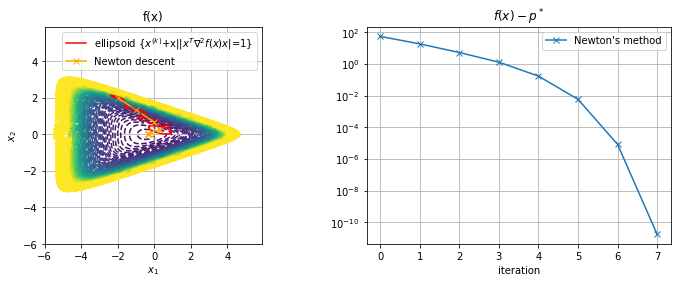

In [32]:
if __name__ == "__main__":
    plt.figure(figsize=(12, 4))
    ax1 = plt.subplot(1, 2, 1)
    ax2 = plt.subplot(1, 2, 2)
    plot_convergence_Newton_method_non_quadratic_problem(ax1, ax2)
    plt.show()